# RAG evaluation: retrieval, prompts and the decisions they led to

**What this notebook covers:** how well localQuill finds the right text for each AI task, what we
measured, what we changed in the config and prompts, and why. The embedding model choice has its
own notebook: `9_embedding_model_decision.ipynb`. The written summary is `docs/rag-evaluation.md`.

Every number is read from files in `evaluation/reports/` (and git history for the old prompts).
Nothing is re-run here. To refresh, run the scripts in `tests/eval/rag/` first.

| § | Content |
|---|---|
| 0 | All decisions at a glance |
| 1 | The test sets: every question and draft |
| 2 | Metrics: what we used before (DeepEval), why we stopped, what we use now |
| 3 | Retrieval: query, chunk size, overlap (Phase 3) |
| 4 | What changed in config and code (before vs. after) |
| 5 | End-to-end: do grammar and feedback get better? (Phase 5, runs 1–8) |
| 6 | Still open |

**How the app uses retrieval (RAG) now.** Each AI task searches Chroma collections and puts the
passages it finds into the prompt:

| Task | Prompt gets | Search query | top_k |
|---|---|---|---|
| Q&A | passages from the user's documents (`userdocs`) + `outline` | the question | 3 + 1 |
| Grammar | fixed guideline file + style-guide passages (`formal` / `fiction`) | 1 problem label picked by the model | 3 |
| Feedback | fixed guideline file + style-guide passages + `outline` | label (style guides), the text (outline) | 2 + 1 |

Style-guide passages are re-ranked by a cross-encoder and marked as references (§5.8).

In [1]:
import difflib
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from rag_eval_helpers import *  # paths, loaders, chart style, metric code shared with the eval

## 0. All decisions at a glance

| # | Area | Before | After | Why (section) |
|---|---|---|---|---|
| 1 | Evaluation method | DeepEval contextual precision/recall with an LLM judge, 4 questions | Hit@k, Recall@k, MRR on snippet-labelled test sets, 50 cases, no judge | judge noise as large as the differences we wanted to see (§2) |
| 2 | Q&A chunk overlap | 400 characters | **0** for user documents and outlines (`UPLOAD_CHUNK_OVERLAP`) | Hit@3 0.69 → 0.88 (§3.3) |
| 3 | Style guide chunks | 1000 / 400 | unchanged | overlap barely matters there; the query is the problem (§3.1, §5.6) |
| 4 | Grammar/feedback guidelines | similarity search only | **hybrid**: fixed guideline file + style-guide search | the search alone rarely found the needed rule (§3.1, §5.1) |
| 5 | Style-guide search query | keywords + text (`retrieval_query` + `text[:2000]`) | **label picked by the model**: 1 item from `problem_labels` | queries written by the model named the wrong problem; feedback: right passage in the top 2 for 0/13 → 9/14 (§3.1, §5.8) |
| 6 | Style-guide search ranking | vector distance | top 30 **re-ranked** by a cross-encoder | with the test set answer as query: Hit@2 0.50 → 0.93 (§5.6) |
| 7 | Style-guide passages in the prompt | plain text | marked `REFERENCE n, from "<guide>" … not the user's text` | the model reviewed guide sentences as the user's text (§5.4) |
| 8 | Feedback / grammar prompts | main | **unchanged** (Structure heading and rewording tried, removed again) | prompts are tested separately; handed over (§5.3) |
| 9 | Thinking (qwen3.5:4b) | on | **off** for grammar and feedback | thinking filled the context, 150 of 180 answers empty (§5.2) |
| 10 | Dev settings in `.env` | 0.8B models, 50-token cap, 30-word cap, context 4096 in code | app defaults (4B, no caps), `NUM_CTX` setting (8192 in `.env`) | the caps cut texts and answers (§4.1) |
| 11 | Fiction style excerpts | in the `fiction` collection | unchanged | checked: they rarely reach the top 3 (§3.5) |
| 12 | Embedding model | nomic-embed-text | unchanged | no model clearly better (notebook 9) |

## 1. The test sets

Two hand-made sets in `tests/eval/rag/`. Each case stores the **ideal passage** ("gold") as a short
text snippet copied from the source, not as a chunk ID. So the same set works for every chunk size:
a retrieved chunk counts as a hit if it covers at least half of the snippet.

Rules for the snippets (checked by `validate_testsets.py`, reviewed by hand):
- The snippet must exist word for word in the text the app indexes.
- It must contain the answer or the rule itself, not just a nearby line or a heading.
- **Q&A:** if a case has several snippets, *all* are needed for a complete answer.
- **Style:** if a case has several snippets, *any one* is useful on its own.

### 1.1 Q&A questions (30)

The user asks about their own uploaded documents: a novel (*The Wonderful Wizard of Oz*),
four C2 exam answers (essays, article, review) and an essay outline.

In [2]:
qa = pd.DataFrame([{
    "id": c["id"], "searches": c["collection"], "question": c["query"],
    "answer must contain": " + ".join(f"“{g['snippet']}”" for g in c["gold"]),
    "source": ", ".join(sorted({g["file"].split("/")[-1] for g in c["gold"]})),
} for c in QA_SET["cases"]])
print(qa["searches"].value_counts().to_string())
qa.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

searches
userdocs    26
outline      3
both         1


id,searches,question,answer must contain,source
qa-oz-01,userdocs,"Where does Dorothy live at the start of the story, and who does she live with?","“Dorothy lived in the midst of the great Kansas prairies, with Uncle Henry, who was a farmer, and Aunt Em”",Fantasy-The Wonderful Wizard.md
qa-oz-02,userdocs,What is Dorothy's house in Kansas like?,"“Their house was small, for the lumber to build it had to be carried by wagon many miles”",Fantasy-The Wonderful Wizard.md
qa-oz-03,userdocs,What does Toto look like?,“Toto was not gray; he was a little black dog”,Fantasy-The Wonderful Wizard.md
qa-oz-04,userdocs,"What does the Scarecrow say he is missing when Dorothy first meets him, and why?","“I don't know anything. You see, I am stuffed, so I have no brains at all”",Fantasy-The Wonderful Wizard.md
qa-oz-05,userdocs,"Why can't the Tin Woodman move his joints when they find him, and what does he need?","“Get an oil-can and oil my joints,"" he answered. ""They are rusted so badly that I cannot move them at all”",Fantasy-The Wonderful Wizard.md
qa-oz-06,userdocs,Why does the Tin Woodman want a heart?,"“no one can love who has not a heart, and so I am resolved to ask Oz to give me one. If he does, I will go back to the Munchkin maiden and marry her”",Fantasy-The Wonderful Wizard.md
qa-oz-07,userdocs,What does the Cowardly Lion hope to get from Oz?,“Do you think Oz could give me courage?”,Fantasy-The Wonderful Wizard.md
qa-oz-08,userdocs,What are the Kalidahs?,“They are monstrous beasts with bodies like bears and heads like tigers”,Fantasy-The Wonderful Wizard.md
qa-oz-09,userdocs,Who calls the field mice back after Toto frightens them?,"“the Tin Woodman caught the dog in his arms and held him tight, while he called to the mice, ""Come back! Come back!”",Fantasy-The Wonderful Wizard.md
qa-oz-10,userdocs,Why does everyone in the Emerald City wear green glasses?,“if you did not wear spectacles the brightness and glory of the Emerald City would blind you”,Fantasy-The Wonderful Wizard.md


### 1.2 Style drafts (20)

Short drafts written for the test, 10 formal and 10 fiction, each with **one known problem**.
The gold passage is the guide advice a writer would need for that problem. These drive both the
retrieval test (§3) and the end-to-end test of grammar and feedback (§5).

In [3]:
style = pd.DataFrame([{
    "id": c["id"], "style": c["style"], "task": c["task"], "known problem": c["issue"],
    "draft": c["draft"], "ideal passage from": ", ".join(sorted({g["file"].split("/")[-1] for g in c["gold"]})),
} for c in STYLE_SET["cases"]])
print(style.groupby(["style", "task"]).size().to_string())
style.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

style    task    
fiction  feedback     4
         grammar      6
formal   feedback    10


id,style,task,known problem,draft,ideal passage from
st-f-01,formal,feedback,weak intensifiers and qualifiers,"The results of the survey were quite surprising and really very important for the company. It is extremely clear that customers are rather unhappy with the new design, and the team was totally convinced that a change was absolutely necessary.",Clear and Concise Writing.pdf
st-f-02,formal,feedback,redundant words and phrases,"In my personal opinion, the final outcome of the study was the end result of past history. The researchers joined together in close proximity and repeated again the experiment, which was completely finished by the month of May.",Clear and Concise Writing.pdf
st-f-03,formal,feedback,contractions and informal register in an academic text,"Climate policy isn't something governments can ignore anymore. They've tried to delay it, but that won't work forever :) Basically, it's a huge deal and everybody knows it, so we shouldn't wait any longer.",Guidelines for Effective Professional and Academic .pdf
st-f-04,formal,feedback,first and second person in a formal essay,"I think this policy is a mistake. You should know that I have read many reports, and in my view you can clearly see that the costs are too high. I feel that we need to reconsider the whole approach.",Guidelines for Effective Professional and Academic .pdf
st-f-05,formal,feedback,no clear thesis: the introduction lists topics without a central claim,Social media is used by many people. There are many platforms such as Instagram and TikTok. Some people use it for news and others for entertainment. In this essay I will talk about social media and some of its aspects.,Harvard_Strategies for Essay Writing--Complete.pdf
st-f-06,formal,feedback,paragraph without a topic sentence,"In 2019, the city added two bus lines. Ticket prices fell by ten per cent. Some residents said they still preferred driving. Parking fees went up in the centre. A survey found that cycling had also increased slightly.",Harvard_Strategies for Essay Writing--Complete.pdf
st-f-07,formal,feedback,missing transitions between ideas,Renewable energy has become cheaper. Many countries still depend on coal. Solar panels need a lot of space. Governments offer subsidies. Wind farms are often opposed by local residents. The climate targets for 2030 are ambitious.,Harvard_Strategies for Essay Writing--Complete.pdf
st-f-08,formal,feedback,vague email subject line,"Subject: Question Dear Professor Miller, I had a question about the assignment that is due next week and wanted to ask whether we can submit it a few days later because of the field trip. Best regards, Anna",Effective Email Communication – The Writing Center.pdf
st-f-09,formal,feedback,literature review that only summarises sources one by one,Smith (2018) studied remote work and found that productivity increased. Jones (2020) also studied remote work and found that employees felt lonely. Brown (2021) looked at managers and found that they preferred office work. Lee (2022) studied remote work in Asia.,Literature Reviews – The Writing Center.pdf
st-f-10,formal,feedback,book review that only retells the plot,The novel begins when Clara moves to London. She finds a job in a bakery and meets Tom. Then her mother falls ill and she goes back home. Later Tom visits her and they decide to open their own shop. At the end the shop is a success.,Book Reviews – The Writing Center.pdf


## 2. Metrics

### 2.1 Before (March–May 2026): DeepEval with an LLM judge

`tests/eval/run_retrieval_eval.py`, 37 runs in `evaluation/reports/DISPRO1/eval_retrieval_results.jsonl`.

| Metric | What it measures | How |
|---|---|---|
| **Contextual precision** (DeepEval) | Are the relevant chunks ranked above the irrelevant ones? | An LLM judge (llama3.1:8b) reads each retrieved chunk and decides if it is relevant to the expected answer |
| **Contextual recall** (DeepEval) | Does the retrieved text contain everything the expected answer needs? | The judge splits the expected answer into statements and checks each against the chunks |
| **Hit rate** | Did the expected *document* appear in the results? | File name match |

The test data was 4 questions about the formal style guides:

In [4]:
old_runs = read_concatenated_json(REPORTS / "DISPRO1" / "eval_retrieval_results.jsonl")
judged = [r for r in old_runs if r.get("average_recall") is not None]
pd.DataFrame([{"question": t["query"], "expected document": t["expected_document"]} for t in judged[0]["per_test"]])

,question,expected document
0,"When you read the assignment prompt, what should you do?",Harvard_Strategies for Essay Writing--Complete.pdf
1,What are the rules for replacing words and phrases to improve writing?,Clear and Concise Writing.pdf
2,What are the core components required to develop a strong argument?,Argumentation Guide.pdf
3,What is the meaning of the word pristine?,C2-Proficiency-CPE-Vocabulary-List-PDF.pdf


**Why it couldn't pick a winner.** Below, every dot is one complete run. All runs here used the same
settings (chunk 1000, overlap 200, top_k 3); only the embedding model changes, and most models were
run several times. Embeddings are deterministic: the same model returns the same chunks every time.
So all the spread within one model is **judge noise**.

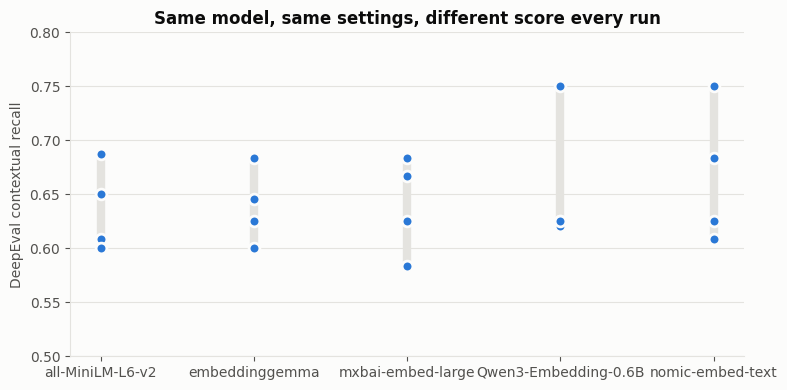

,runs,recall_min,recall_max,hit_rate,minutes_per_run,spread
model,,,,,,
all-MiniLM-L6-v2,4,0.60,0.69,1.0,5.93,0.09
embeddinggemma,4,0.60,0.68,1.0,6.53,0.08
mxbai-embed-large,4,0.58,0.68,1.0,6.49,0.10
Qwen3-Embedding-0.6B,4,0.62,0.75,1.0,7.38,0.13
nomic-embed-text,4,0.61,0.75,1.0,16.05,0.14


In [5]:
same = pd.DataFrame([{
    "model": r["embedding_model"].split("/")[-1].split(":")[0].replace("-Q8_0", ""),
    "recall": r["average_recall"], "precision": r["average_precision"], "hit rate": r["average_hit_rate"],
    "minutes": r["duration_seconds"] / 60,
} for r in judged if (r["chunk_size"], r["chunk_overlap"], r["top_k"]) == (1000, 200, 3)])
same["model"] = same["model"].replace({"all-minilm-l6-v2": "all-MiniLM-L6-v2"})
order = same.groupby("model")["recall"].mean().sort_values().index

fig, ax = plt.subplots(figsize=(8, 4))
for x, m in enumerate(order):
    vals = same.loc[same["model"] == m, "recall"]
    ax.plot([x, x], [vals.min(), vals.max()], color=GRID, linewidth=6, solid_capstyle="round", zorder=1)
    ax.scatter([x] * len(vals), vals, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=2)
ax.set_xticks(range(len(order)), order)
ax.set_ylabel("DeepEval contextual recall")
ax.set_ylim(0.5, 0.8)
ax.set_title("Same model, same settings, different score every run")
plt.tight_layout(); plt.show()

spread = same.groupby("model").agg(runs=("recall", "size"), recall_min=("recall", "min"), recall_max=("recall", "max"),
                                   hit_rate=("hit rate", "mean"), minutes_per_run=("minutes", "mean")).round(2)
spread["spread"] = (spread["recall_max"] - spread["recall_min"]).round(2)
spread.loc[order]

**Why we changed:**
- **Noise ≥ differences.** One model's own spread (up to ~0.15 recall) is as large as the gap between
  the best and worst model. A ranking from one run is luck.
- **Hit rate is always 1.0.** Every model found the right document every time, so it separates nothing.
  "Right document" is too coarse anyway: a 300-page guide is "right" even if the chunk is useless.
- **Too little and the wrong kind of data.** 4 questions, all about the formal guides, none like what
  the app really sends (grammar/feedback search with the user's draft, Q&A over uploads).
- **Slow and needs a judge model.** 6–16 minutes per run for 4 questions (table above).

### 2.2 Now: rank metrics on labelled snippets (no judge)

For each case the eval records the **rank** at which each gold snippet's chunk appears (1 = first
result, none = not in the top 8). Then:

| Metric | Definition | Read as |
|---|---|---|
| **Hit@k** | share of cases where at least one gold snippet is in the top *k* | "how often does the model get *something* useful?" |
| **Recall@k** | per case, share of its gold snippets in the top *k*, averaged | for Q&A cases needing several passages: how complete the answer can be |
| **Complete@k** | share of cases where *all* gold snippets are in the top *k* | Q&A: answer fully supported |
| **MRR** | mean of 1 / rank of the first hit (0 if none) | rewards putting the answer first |

*k* is what the app actually sends: **3 for Q&A and grammar, 2 for feedback**. A chunk counts as
containing a snippet when it covers at least 50% of the snippet's characters (snippets can be split
across two chunks).

Worked example with the real metric function:

In [6]:
toy = [
    {"ranks": [1]},        # answer is the first result
    {"ranks": [4]},        # found, but only at rank 4
    {"ranks": [2, None]},  # needs two passages, only one found
    {"ranks": [None]},     # not found in the top 8
]
pd.DataFrame({f"k={k}": metrics(toy, k) for k in (1, 3, 5)}).drop("n").round(2)

,k=1,k=3,k=5
hit,0.25,0.50,0.75
recall,0.25,0.38,0.62
complete,0.25,0.25,0.50
mrr,0.44,0.44,0.44


Why this is better here:
- **Deterministic and exact:** same setup → same number. A difference of one case is real.
- **Fast:** a whole setup (50 cases × all query styles) runs in seconds once the index exists, so
  we could test 38 setups instead of a handful.
- **Measures what the app does:** same queries, same *k*, same collections as the tasks.

Limit: it only checks the passages we labelled. Another chunk could also be useful. That's why §5
also checks the final output of the tasks.

### 2.3 End-to-end metric (§5)

Retrieval is only a means. §5 runs grammar and feedback on the 20 drafts and scores the **output**:
2 = the known problem is fixed (grammar) / named with a usable fix (feedback), 1 = partly, 0 = missed.
A judge model (`ministral-3:8b`) scored all outputs; feedback was also **graded by hand** because the
judge turned out to be unreliable (§5.3).

## 3. Retrieval: query, chunk size and overlap (Phase 3)

18 setups with nomic-embed-text: chunk size 500 / 1000 / 1500 × overlap 0 / 200 / 400 × prefixes
off / on. Raw results: `evaluation/reports/RAG/results.jsonl`.

### 3.1 Grammar and feedback: the query is the problem

Grammar and feedback search the style guides. Before this work, the search query was a fixed keyword
list plus the first 2,000 characters of the user's text. We tried other ways to build the query on the
same index (chunk 1000, overlap 400 = the app's settings). Each query is named after where it comes
from in the code. Example: test text **st-f-09**, a literature review that only summarises its sources
one by one ("draft" is the field name of a test text in `testset_style.json`).

| Query | Where it comes from in the code | Example search text (st-f-09) |
|---|---|---|
| **keywords + text** (app before) | `retrieval_query` + `text[:2000]` (first 2,000 characters of the user's text) | "style tone register passive voice … readability" + "Smith (2018) studied remote work and found…" |
| **text only** | `text[:2000]` | "Smith (2018) studied remote work and found…" |
| **keywords only** | `retrieval_query` in `feedback.py` / `grammar.py` | "style tone register passive voice word choice clarity ambiguity readability" |
| **query written by the model** | the model writes a ≤12-word query first (the old `STYLE_QUERY_PROMPT`; here `ministral-3:8b`, in run 5 qwen3.5:4b) | "How to vary sentence structure in academic writing" |
| **label picked by the model** (app now) | `style_query`: the model picks 1 item from `problem_labels` (qwen3.5:4b) | "literature review that summarises sources one by one instead of synthesising them" |
| **test set answer** (best case) | the `issue` field in `testset_style.json`, written by us. The app can't know it; it shows how good the search could be with a perfect query | "literature review that only summarises sources one by one" |

The label picked by the model was added later (§5.8) and measured separately (`check_label_queries.py`, all 20 test
texts), with plain vector search and with re-ranking as in the app now.

**How to read the "best case" bars (grey).** The app has to find out what is wrong with a text before
it can search for advice; the model does that by picking a label, and sometimes it picks the wrong
one. The best case skips that step: we hand the search the problem we wrote into the test set, as if
the model *always* named the right problem. It is not a setup the app could use; it shows how far
the search itself can go. The app now (label picked by the model + re-ranked) should therefore be
compared with the best case **using the same search method** (+ re-ranked): the gap between those
two bars is only the model's wrong picks.

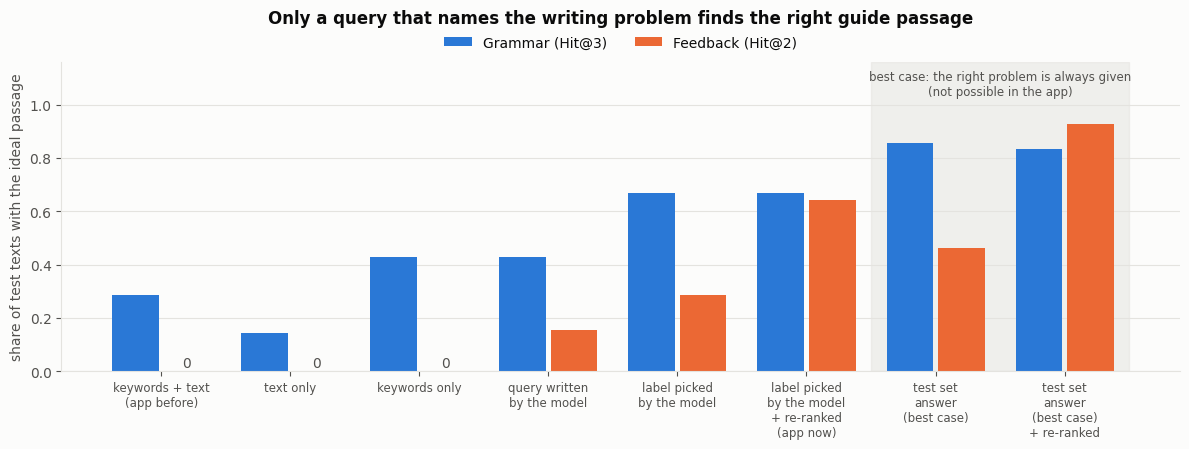

Compare 'label picked by the model + re-ranked (app now)' with 'test set answer + re-ranked':
same search, the only difference is whether the model named the right problem.
Bars without '+ re-ranked' use plain vector search. Phase 3 counted st-f-02 as grammar (7 grammar / 13
feedback texts); the label check and the re-ranked best case have it as feedback (6 / 14).


,Grammar (Hit@3),Feedback (Hit@2)
keywords + text (app before),0.29,0.00
text only,0.14,0.00
keywords only,0.43,0.00
query written by the model,0.43,0.15
label picked by the model,0.67,0.29
label picked by the model + re-ranked (app now),0.67,0.64
test set answer (best case),0.86,0.46
test set answer (best case) + re-ranked,0.83,0.93


In [7]:
r = run()
styles = ["task", "draft", "keywords", "llm", "issue"]
lab20 = pd.DataFrame(json.loads((RAG / "label_queries_check_all_20.json").read_text()))
def label_hit(task, col):
    sub = lab20[lab20["task"] == task]
    return sub[col].apply(lambda x: pd.notna(x) and x <= APP_TOP_K[task]).mean()
q = pd.DataFrame({
    f"Grammar (Hit@{APP_TOP_K['grammar']})": [score(r, "style", GRAMMAR, s, APP_TOP_K["grammar"]) for s in styles]
        + [label_hit("grammar", "rank_vector"), label_hit("grammar", "rank_rerank")],
    f"Feedback (Hit@{APP_TOP_K['feedback']})": [score(r, "style", FEEDBACK, s, APP_TOP_K["feedback"]) for s in styles]
        + [label_hit("feedback", "rank_vector"), label_hit("feedback", "rank_rerank")],
}, index=[QUERY_NAMES[s] for s in styles] + [QUERY_NAMES["label"], QUERY_NAMES["label"] + " + re-ranked (app now)"])
opts = pd.DataFrame(json.loads((RAG / "retrieval_options.json").read_text()))
best = opts[(opts["query"] == "issue") & (opts["search"] == "vector+rerank") & (opts["chunks"] == "1000/400")]
best_hit = lambda task: best[best["group"].str.startswith(task)]["ranks"].apply(
    lambda rs: any(x and x <= APP_TOP_K[task] for x in rs)).mean()
q.loc[QUERY_NAMES["issue"] + " + re-ranked"] = [best_hit("grammar"), best_hit("feedback")]
q = q.iloc[[0, 1, 2, 3, 5, 6, 4, 7]]  # best case last
wrap = lambda t: t.replace(" (", "\n(").replace(" + re-ranked", "\n+ re-ranked").replace("test set answer", "test set\nanswer").replace("written by", "written\nby").replace("picked by", "picked\nby").replace("answer ", "answer\n")

fig, ax = plt.subplots(figsize=(12, 4.6))
grouped_bars(ax, q.rename(index=wrap), [BLUE, ORANGE], "share of test texts with the ideal passage")
ax.axvspan(5.5, 7.5, color=GRID, alpha=0.5, zorder=0)
ax.set_ylim(0, 1.16); ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.text(6.5, 1.13, "best case: the right problem is always given\n(not possible in the app)", ha="center", va="top", fontsize=8.5, color=INK_2)
ax.tick_params(axis="x", labelsize=8.5)
ax.set_title("Only a query that names the writing problem finds the right guide passage", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
print("Compare 'label picked by the model + re-ranked (app now)' with 'test set answer + re-ranked':")
print("same search, the only difference is whether the model named the right problem.")
print("Bars without '+ re-ranked' use plain vector search. Phase 3 counted st-f-02 as grammar (7 grammar / 13")
print("feedback texts); the label check and the re-ranked best case have it as feedback (6 / 14).")
q.round(2)

The user's text is *about* something (a harbour, climate policy, a lighthouse). With the text in the
query, the search returns guide passages about that topic, not about the writing problem: a lighthouse
story gets passages about boats and the sea, a policy essay gets grant-proposal budgets. Feedback
with **keywords + text** found the ideal passage in **0 of 13** cases. The **label picked by the
model**, re-ranked (the app now), finds it for 9 of 14 feedback and 4 of 6 grammar texts. With the
same search, the best case finds it for 13 of 14 and 5 of 6: the app reaches about 70–80% of what the
search could do if the right problem were always known.

Even with more chunks, keywords + text doesn't catch up (Hit@k for k = 1 … 8):

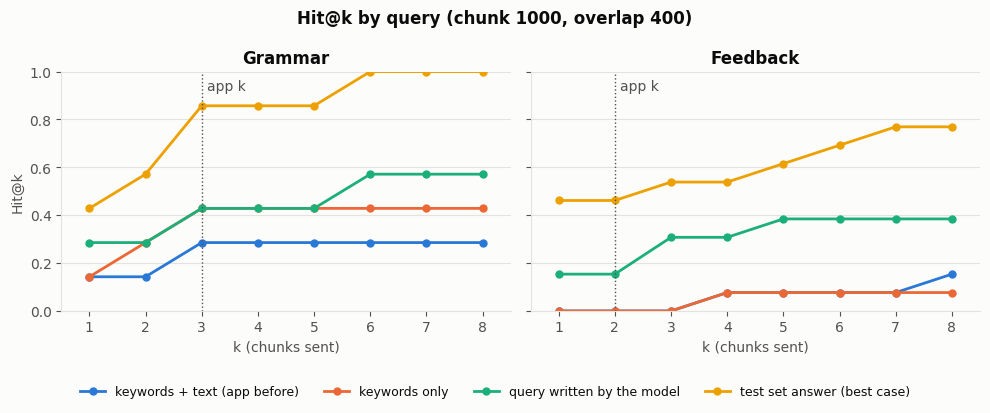

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ks = range(1, K_MAX + 1)
for ax, (title, groups) in zip(axes, [("Grammar", GRAMMAR), ("Feedback", FEEDBACK)]):
    for s, color in zip(["task", "keywords", "llm", "issue"], [BLUE, ORANGE, AQUA, YELLOW]):
        ys = [score(r, "style", groups, s, k) for k in ks]
        ax.plot(ks, ys, color=color, linewidth=2, marker="o", markersize=5, label=QUERY_NAMES[s])
    ax.axvline(APP_TOP_K[title.lower()], color=INK_2, linestyle=":", linewidth=1)
    ax.text(APP_TOP_K[title.lower()] + 0.1, 0.97, "app k", color=INK_2, va="top")
    ax.set_title(title); ax.set_xlabel("k (chunks sent)"); ax.set_xlim(0.5, K_MAX + 0.5); ax.set_ylim(0, 1)
axes[0].set_ylabel("Hit@k")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize=9)
fig.suptitle("Hit@k by query (chunk 1000, overlap 400)", fontweight="bold")
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

What the **query written by the model** (`ministral-3:8b`) looks like next to the **test set
answer** and the **label picked by the model** (qwen3.5:4b, app now). The written query is close
for grammar, often vaguer for feedback (it names tone or wordiness instead of e.g. the missing
thesis). Both the written query and the label cost one extra short model call per request.

In [9]:
lq = json.loads((RAG / "llm_queries_by_case.json").read_text()); lq.pop("_note")
picked = {row["id"]: row["picked"][0] for row in json.loads((RAG / "label_queries_check_all_20.json").read_text())}
t = pd.DataFrame(lq).T[["issue", "llm_query"]]
t["label"] = [picked.get(i, "") for i in t.index]
t.rename(columns={"issue": QUERY_NAMES["issue"], "llm_query": QUERY_NAMES["llm"] + " (ministral-3:8b)",
                  "label": QUERY_NAMES["label"] + " (qwen3.5:4b)"})

,test set answer (best case),query written by the model (ministral-3:8b),label picked by the model (qwen3.5:4b)
st-f-01,weak intensifiers and qualifiers,Overuse of intensifiers and redundant adjectives,weak intensifiers and qualifiers
st-f-02,redundant words and phrases,Comma splice and run-on sentence correction,first or second person in formal writing
st-f-03,contractions and informal register in an academic text,Tone: overly casual and informal,"informal register, contractions or slang"
st-f-04,first and second person in a formal essay,Passive voice and informal tone in formal writing,first or second person in formal writing
st-f-05,no clear thesis: the introduction lists topics without a central claim,Lack of cohesive thesis-driven structure,first or second person in formal writing
st-f-06,paragraph without a topic sentence,Inconsistent sentence structure and fragmented transitions,no clear thesis or central claim
st-f-07,missing transitions between ideas,Fragmented sentences with no cohesive structure or logical flow,no clear thesis or central claim
st-f-08,vague email subject line,Lack of formal email structure and professional tone,email with a vague subject line
st-f-09,literature review that only summarises sources one by one,Lack of cohesive argumentative structure in paragraph,literature review that summarises sources one by one instead of synthesising them
st-f-10,book review that only retells the plot,Lacks cohesive narrative flow and emotional depth,book review that only retells the plot instead of evaluating the book


**Same pattern for every chunk size and overlap.** Mean over all 18 setups:

In [10]:
rows = []
for r_ in [x for x in RUNS if x["model"] == "nomic-embed-text"]:
    for s in styles:
        rows.append({"setup": f"{r_['chunk_size']}/{r_['overlap']} prefix {'on' if r_['prefixes'] else 'off'}", "query": s,
                     "grammar Hit@3": score(r_, "style", GRAMMAR, s, 3), "feedback Hit@2": score(r_, "style", FEEDBACK, s, 2)})
allq = pd.DataFrame(rows)
summary = allq.groupby("query")[["grammar Hit@3", "feedback Hit@2"]].agg(["mean", "min", "max"]).loc[styles].round(2)
summary.rename(index=QUERY_NAMES)

grammar Hit@3             feedback Hit@2        \
                                      mean   min   max           mean   min   
query                                                                         
keywords + text (app before)          0.32  0.14  0.57           0.01  0.00   
text only                             0.05  0.00  0.14           0.00  0.00   
keywords only                         0.35  0.29  0.43           0.02  0.00   
query written by the model            0.38  0.29  0.57           0.15  0.00   
test set answer (best case)           0.77  0.57  0.86           0.58  0.31   

                                    
                               max  
query                               
keywords + text (app before)  0.08  
text only                     0.00  
keywords only                 0.08  
query written by the model    0.31  
test set answer (best case)   0.77

**Consequence (decision 4):** the search alone can't be trusted to deliver the rule a draft needs.
The app now always puts a short hand-picked guideline file in the prompt and adds the search results
after it (*hybrid*, §4.2). A better query turned out to be the key: §5.5–5.8.

### 3.2 Overlap and chunk size for the style guides

For grammar and feedback, chunk size and overlap change little next to the query. Grammar Hit@3 /
feedback Hit@2 with **keywords + text** (the app's query at the time), prefixes off:

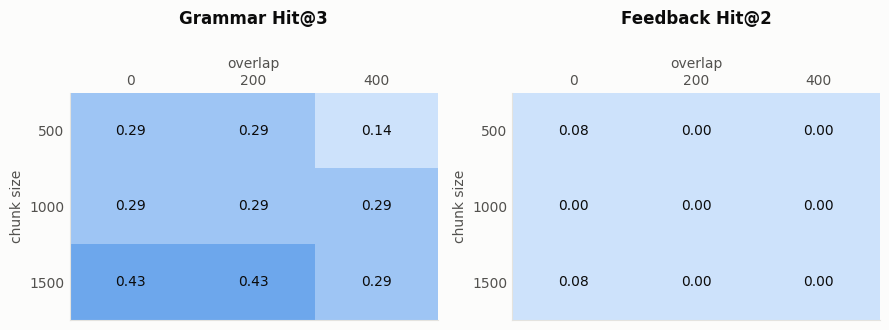

In [11]:
grid_g = pd.DataFrame({o: [score(run(chunk=c, overlap=o), "style", GRAMMAR, "task", 3) for c in (500, 1000, 1500)]
                       for o in (0, 200, 400)}, index=[500, 1000, 1500])
grid_f = pd.DataFrame({o: [score(run(chunk=c, overlap=o), "style", FEEDBACK, "task", 2) for c in (500, 1000, 1500)]
                       for o in (0, 200, 400)}, index=[500, 1000, 1500])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, g, t in zip(axes, [grid_g, grid_f], ["Grammar Hit@3", "Feedback Hit@2"]):
    score_grid(ax, g, vmax=1, fmt="{:.2f}", cmap=RAMP_CMAP)
    ax.set_title(t, pad=24); ax.set_ylabel("chunk size"); ax.set_xlabel("overlap")
    ax.xaxis.set_label_position("top")
plt.tight_layout(); plt.show()

### 3.3 Q&A: chunk 1000 with no overlap

Q&A searches the user's uploads with the question as the query. Here the setup matters a lot:

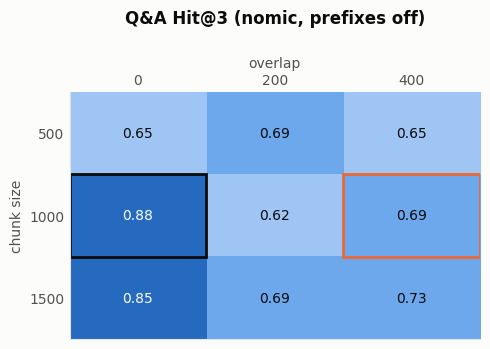

orange frame = app before (1000/400), black frame = app now (1000/0)


In [12]:
k = APP_TOP_K["userdocs"]
qa_grid = pd.DataFrame({o: [score(run(chunk=c, overlap=o), "qa", {"userdocs"}, "question", k) for c in (500, 1000, 1500)]
                        for o in (0, 200, 400)}, index=[500, 1000, 1500])
fig, ax = plt.subplots(figsize=(5, 3.6))
score_grid(ax, qa_grid, vmin=0.5, vmax=1, fmt="{:.2f}", cmap=RAMP_CMAP)
ax.set_title(f"Q&A Hit@{k} (nomic, prefixes off)", pad=24); ax.set_ylabel("chunk size"); ax.set_xlabel("overlap")
ax.xaxis.set_label_position("top")
ax.add_patch(plt.Rectangle((1.5, 0.5), 1, 1, fill=False, edgecolor=ORANGE, linewidth=2))
ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=2))
plt.tight_layout(); plt.show()
print("orange frame = app before (1000/400), black frame = app now (1000/0)")

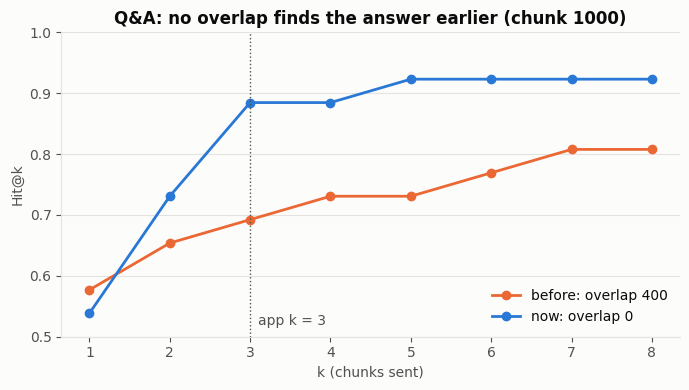

,before 1000/400,now 1000/0
Hit@3,0.69,0.88
Recall@3,0.69,0.88
Complete@3,0.69,0.88
MRR,0.65,0.69


In [13]:
before, after = run(chunk=1000, overlap=400), run(chunk=1000, overlap=0)
qa_m = pd.DataFrame({name: {m: metrics(cases_of(rr, "qa", {"userdocs"}, "question"), 3)[m] for m in ("hit", "recall", "complete", "mrr")}
                     for name, rr in [("before 1000/400", before), ("now 1000/0", after)]}).round(2)
qa_m.index = ["Hit@3", "Recall@3", "Complete@3", "MRR"]

fig, ax = plt.subplots(figsize=(7, 4))
ks = range(1, K_MAX + 1)
for name, rr, color in [("before: overlap 400", before, ORANGE), ("now: overlap 0", after, BLUE)]:
    ys = [score(rr, "qa", {"userdocs"}, "question", k_) for k_ in ks]
    ax.plot(ks, ys, color=color, linewidth=2, marker="o", markersize=6, label=name)
ax.axvline(3, color=INK_2, linestyle=":", linewidth=1); ax.text(3.1, 0.52, "app k = 3", color=INK_2)
ax.set_xlabel("k (chunks sent)"); ax.set_ylabel("Hit@k"); ax.set_ylim(0.5, 1)
ax.set_title("Q&A: no overlap finds the answer earlier (chunk 1000)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
qa_m

Why: with 400 characters of overlap, neighbouring chunks share almost half their text. A question
then pulls in 2–3 near-copies of the same passage, which fill the top 3 and push out the other
passage the answer needs. Per question (rank of the first gold chunk, – = not in the top 8):

In [14]:
def ranks(rr):
    return {c["id"]: min((x for x in c["ranks"] if x), default=None) for c in cases_of(rr, "qa", {"userdocs"}, "question")}
qd = {c["id"]: c["query"] for c in QA_SET["cases"]}
cmp = pd.DataFrame({"before (1000/400)": ranks(before), "now (1000/0)": ranks(after)})
cmp.insert(0, "question", [qd[i] for i in cmp.index])
rank = lambda v: 99 if pd.isna(v) else v  # not in the top 8 counts as worst
cmp["change"] = [("better" if rank(b) > rank(a) else "worse" if rank(b) < rank(a) else "")
                 for b, a in zip(cmp.iloc[:, 1], cmp.iloc[:, 2])]
cmp["in top 3"] = [("now" if rank(a) <= 3 < rank(b) else "lost" if rank(b) <= 3 < rank(a) else "")
                   for b, a in zip(cmp.iloc[:, 1], cmp.iloc[:, 2])]
print(cmp["change"].replace("", "same").value_counts().to_string())
print(cmp["in top 3"].replace("", "unchanged").value_counts().to_string())
for col in ("before (1000/400)", "now (1000/0)"):
    cmp[col] = [("–" if pd.isna(v) else str(int(v))) for v in cmp[col]]
cmp

change
same      15
better     7
worse      4
in top 3
unchanged    19
now           6
lost          1


,question,before (1000/400),now (1000/0),change,in top 3
qa-oz-01,"Where does Dorothy live at the start of the story, and who does she live with?",–,3,better,now
qa-oz-02,What is Dorothy's house in Kansas like?,6,1,better,now
qa-oz-03,What does Toto look like?,1,1,,
qa-oz-04,"What does the Scarecrow say he is missing when Dorothy first meets him, and why?",2,2,,
qa-oz-05,"Why can't the Tin Woodman move his joints when they find him, and what does he need?",1,3,worse,
qa-oz-06,Why does the Tin Woodman want a heart?,7,5,better,
qa-oz-07,What does the Cowardly Lion hope to get from Oz?,1,2,worse,
qa-oz-08,What are the Kalidahs?,1,1,,
qa-oz-09,Who calls the field mice back after Toto frightens them?,1,1,,
qa-oz-10,Why does everyone in the Emerald City wear green glasses?,2,2,,


**Decision 2:** user uploads and outlines are now split with no overlap (`UPLOAD_CHUNK_OVERLAP=0`,
`src/vector_db/documents.py`). The style guides keep `CHUNK_OVERLAP=400` because they're indexed
once and §3.2 showed no clear gain there. Documents uploaded before the change keep their old chunks
until they are uploaded again.

### 3.4 Prefixes

Some embedding models expect a short instruction before queries and documents
(nomic: `search_query:` / `search_document:`). For nomic they didn't help on Q&A: details in
notebook 9.

### 3.5 Fiction style excerpts: checked, left as is

The `fiction` collection holds the guides and six short genre excerpts added on purpose (Dracula,
Sherlock Holmes, Hamlet…). The question was whether these excerpts push guide passages out of the
results. Checked with `tests/eval/rag/check_fiction_excerpts.py`:

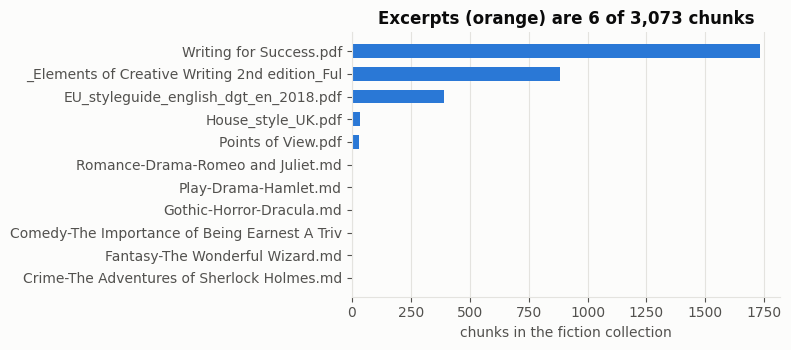

,query_style,keywords + text (app before),text only,keywords only
id,task,,,
st-p-01,grammar,0,0,0
st-p-02,grammar,0,1,0
st-p-03,grammar,0,0,0
st-p-04,grammar,0,0,0
st-p-05,feedback,2,1,0
st-p-06,feedback,1,1,0
st-p-07,feedback,0,0,0
st-p-08,feedback,0,0,0
st-p-09,grammar,0,1,0


In [15]:
fx = json.loads((RAG / "fiction_excerpts_check.json").read_text())
src = pd.Series(fx["chunks_per_source"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [ORANGE if n.endswith(".md") else BLUE for n in src.index]
ax.barh([n[:45] for n in src.index], src.values, color=colors, height=0.6)
ax.set_xlabel("chunks in the fiction collection"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Excerpts (orange) are 6 of 3,073 chunks")
plt.tight_layout(); plt.show()

top = pd.DataFrame(fx["cases"])
top["excerpts in top 3"] = top["top3"].apply(lambda t: t.count("excerpt"))
top.pivot(index=["id", "task"], columns="query_style", values="excerpts in top 3")[["task", "draft", "keywords"]].rename(columns=QUERY_NAMES)

With **keywords + text** the excerpts take 3 of 30 top-3 slots, all in two feedback cases, none
in grammar. In st-p-05 the excerpt even made the feedback genre-aware ("gothic horror register").
**Decision 11:** no change.

## 4. What changed in config and code

"Before" = commit `1f8295c` (main before this work), read from git. "After" = the files now.
The feedback and grammar **prompt templates are unchanged** (two prompt changes were tried in run 3
and removed again, §5.3); what changed is what goes into `{guidelines}` and how it is found.

### 4.1 Settings

In [16]:
pd.DataFrame([
    ["UPLOAD_CHUNK_OVERLAP (.env, new)", "– (used CHUNK_OVERLAP = 400)", "0", "§3.3: Q&A Hit@3 0.69 → 0.88"],
    ["CHUNK_OVERLAP (.env)", "400", "400 (style guides only)", "§3.2: no clear gain from changing"],
    ["TaskConfig.think (src/config.py, new)", "– (model default: on)", "False for grammar, feedback", "§5.2: thinking filled the context, empty answers"],
    ["NUM_CTX (.env, new)", "4096, fixed in src/llm/factory.py", "setting, default 4096 (.env: 8192)", "room for thinking or more passages; eval prompts used ≤ ~1,700 tokens"],
    ["RERANK_MODEL (new)", "–", "cross-encoder/ms-marco-MiniLM-L-6-v2", "§5.6: re-ranking finds the right passage for a good query"],
    ["GRAMMAR/QA/FEEDBACK_MODEL (.env)", "qwen3.5:0.8b (dev)", "qwen3.5:4b (app default)", "the model all results here are for"],
    ["GRAMMAR_MAX_WORDS (.env)", "30 (dev)", "300", "30 words cut texts after 1–2 sentences"],
    ["LIMIT_TOKEN_NUMBER (.env)", "50 (dev)", "0 = no cap", "50 tokens cut answers mid-sentence"],
    ["Embedding model", "nomic-embed-text", "nomic-embed-text", "notebook 9"],
], columns=["setting", "before", "after", "why"])

,setting,before,after,why
0,"UPLOAD_CHUNK_OVERLAP (.env, new)",– (used CHUNK_OVERLAP = 400),0,§3.3: Q&A Hit@3 0.69 → 0.88
1,CHUNK_OVERLAP (.env),400,400 (style guides only),§3.2: no clear gain from changing
2,"TaskConfig.think (src/config.py, new)",– (model default: on),"False for grammar, feedback","§5.2: thinking filled the context, empty answers"
3,"NUM_CTX (.env, new)","4096, fixed in src/llm/factory.py","setting, default 4096 (.env: 8192)","room for thinking or more passages; eval prompts used ≤ ~1,700 tokens"
4,RERANK_MODEL (new),–,cross-encoder/ms-marco-MiniLM-L-6-v2,§5.6: re-ranking finds the right passage for a good query
5,GRAMMAR/QA/FEEDBACK_MODEL (.env),qwen3.5:0.8b (dev),qwen3.5:4b (app default),the model all results here are for
6,GRAMMAR_MAX_WORDS (.env),30 (dev),300,30 words cut texts after 1–2 sentences
7,LIMIT_TOKEN_NUMBER (.env),50 (dev),0 = no cap,50 tokens cut answers mid-sentence
8,Embedding model,nomic-embed-text,nomic-embed-text,notebook 9


### 4.2 How grammar and feedback get their guidelines (`src/tasks/base.py`)

Before: one similarity search with **keywords + text** (`retrieval_query` + `text[:2000]`). After:
1. the fixed guideline file for the task and style;
2. `style_query`: the task model picks **one** label from `problem_labels` (one extra short call);
3. `search_guides`: the label is searched, the top 30 are re-ranked, the best are kept;
4. the passages are marked as references (`format_references`, `src/rag/retriever.py`).

Lines starting with `-` were removed, `+` added.

In [17]:
def show_diff(path):
    old, new = git_show(path).splitlines(), (ROOT / path).read_text().splitlines()
    print("\n".join(difflib.unified_diff(old, new, f"before ({BEFORE_COMMIT})", "after", n=1, lineterm="")))
show_diff("src/tasks/base.py")

--- before (1f8295c)
+++ after
@@ -2,2 +2,3 @@
 import time
+from pathlib import Path
 from src.config import TaskConfig
@@ -5,3 +6,3 @@
 from src.guardrails.notices import report_text
-from src.rag.retriever import retrieve, format_context
+from src.rag.retriever import format_references, retrieve_reranked
 from src.tasks.utility import format_attachments, truncate_by_paragraph
@@ -11,2 +12,37 @@
 
+# Hand-picked guide passages per task and style ({task}_{style}.md). Always in the prompt, so the
+# core rules are there even when the search picks the wrong passage (docs/rag-evaluation.md).
+GUIDELINES_DIR = Path(__file__).parent / "guidelines"
+
+# Search query for the style guides. The model picks the text's main problem from a fixed list of
+# guide topics (Task.problem_labels) and that label is the search query. A query built from the text
+# finds passages about its topic; a free-text query written by a small model often names the wrong
+# problem; a label finds the right passage f

### 4.3 Label lists and search calls (`src/tasks/feedback.py`, `src/tasks/grammar.py`)

The labels are topics of the guides in `data/styles/`. The model chooses from them (multiple choice)
instead of writing a query. The prompt templates in these files are the same as before.

In [18]:
show_diff("src/tasks/feedback.py")
show_diff("src/tasks/grammar.py")

--- before (1f8295c)
+++ after
@@ -1,3 +1,3 @@
 import logging
-from .base import Task
+from .base import Task, join_guidelines
 from src.rag.retriever import retrieve_from
@@ -11,4 +11,41 @@
     retrieval_query = "style tone register passive voice word choice clarity ambiguity readability"
+    query_focus = "style, tone and structure"
+    # Guide topics (style guides in data/styles/) the model picks from to search them.
+    problem_labels_by_style = {
+        "formal": [
+            "weak intensifiers and qualifiers",
+            "redundant or wordy phrases",
+            "informal register, contractions or slang",
+            "first or second person in formal writing",
+            "no clear thesis or central claim",
+            "paragraph without a topic sentence stating its main idea",
+            "missing transitions between ideas",
+            "literature review that summarises sources one by one instead of synthesising them",
+            "book review that only retell

### 4.4 Re-ranking: an extra local model (`src/rag/retriever.py`)

**What it is.** `cross-encoder/ms-marco-MiniLM-L-6-v2`, a small text model (22.7 million parameters,
88 MB) that gives one number per (query, passage) pair: how well the passage answers the query. It
is **not an LLM**: it does not write text and cannot follow instructions; it only scores. It is the
same kind of model as the guardrail classifier (`protectai/deberta-v3-base-prompt-injection-v2`),
which scores whether a text is a prompt injection.

**How it differs from the embedding model and the LLM:**

| Model | Role in the app | Reads | Output | Size |
|---|---|---|---|---|
| `nomic-embed-text` (Ollama) | vector search | query and passage **separately**, each turned into a vector | similarity of the two vectors | 274 MB |
| `ms-marco-MiniLM-L-6-v2` (re-ranker) | reorders the top 30 of the vector search | query and passage **together**, word by word | one relevance score | 88 MB |
| `qwen3.5:4b` (Ollama, LLM) | picks the label, writes the feedback / correction | the whole prompt | text | 3.3 GB |

The embedding model compares two summaries (vectors) that were made without knowing each other. That
is fast enough to search thousands of chunks, but coarse: a passage that merely uses similar words
can rank first. The re-ranker reads the label and the passage side by side, so it can tell "advice
about transitions" from "a passage that happens to mention transitions". It is too slow for the
whole collection, so it only reorders the 30 best vector results: about 0.5 s on the CPU per request
(measured: 30 pairs in 0.55 s, loading 1.7 s once).

**Why it is needed.** Without it, even the right label often doesn't bring the right passage into
the top 2. Right passage in the top *k* the app sends (feedback 2, grammar 3):

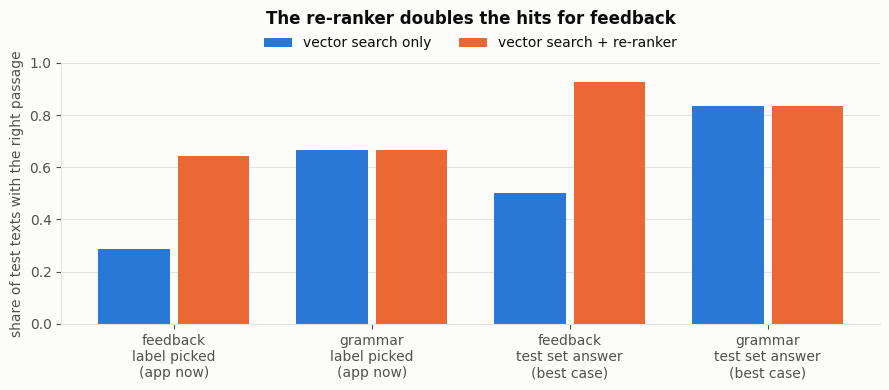

,vector search only,vector search + re-ranker
feedback\nlabel picked\n(app now),0.29,0.64
grammar\nlabel picked\n(app now),0.67,0.67
feedback\ntest set answer\n(best case),0.50,0.93
grammar\ntest set answer\n(best case),0.83,0.83


In [19]:
lab20 = pd.DataFrame(json.loads((RAG / "label_queries_check_all_20.json").read_text()))
opts = pd.DataFrame(json.loads((RAG / "retrieval_options.json").read_text()))
def opt_hit(task, search):
    sub = opts[(opts["query"] == "issue") & (opts["search"] == search) & (opts["chunks"] == "1000/400")
               & opts["group"].str.startswith(task)]
    return sub["ranks"].apply(lambda rs: any(x and x <= APP_TOP_K[task] for x in rs)).mean()
def lab_hit(task, col):
    sub = lab20[lab20["task"] == task]
    return sub[col].apply(lambda x: pd.notna(x) and x <= APP_TOP_K[task]).mean()
rr = pd.DataFrame({
    "vector search only": [lab_hit("feedback", "rank_vector"), lab_hit("grammar", "rank_vector"),
                           opt_hit("feedback", "vector"), opt_hit("grammar", "vector")],
    "vector search + re-ranker": [lab_hit("feedback", "rank_rerank"), lab_hit("grammar", "rank_rerank"),
                                  opt_hit("feedback", "vector+rerank"), opt_hit("grammar", "vector+rerank")],
}, index=["feedback\nlabel picked\n(app now)", "grammar\nlabel picked\n(app now)",
          "feedback\ntest set answer\n(best case)", "grammar\ntest set answer\n(best case)"])
fig, ax = plt.subplots(figsize=(9, 4))
grouped_bars(ax, rr, [BLUE, ORANGE], "share of test texts with the right passage")
ax.set_title("The re-ranker doubles the hits for feedback", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
rr.round(2)

- **Feedback:** with the label picked by the model, 4 of 14 → **9 of 14** texts get the right
  passage. This is where the style-guide search becomes useful at all (§5.8).
- **Grammar:** no change (4 of 6 either way); grammar labels like "comma splice" already match the
  guide's wording.

**Local, like the rest of the app.** The model file is downloaded **once** from Hugging Face (as the
guardrail model is, and as Ollama models are downloaded from Ollama) into `~/.cache/huggingface/`
(in Docker: the `hf_cache` volume). After that it runs on the user's machine; **the user's text is
never sent anywhere**. If the file is missing and there is no internet, the app logs a warning and
keeps the plain vector order (`get_reranker`), so nothing breaks; the search is just less accurate.
The model can be changed with `RERANK_MODEL` in `.env`.

**Alternatives that were not chosen:** keyword search (BM25) combined with vector search needs no
model, but did not help with the label query (§5.6); asking the LLM to choose among the 30 passages
would take far longer than 0.5 s and is less reliable with a 4B model.

The code: `retrieve_reranked` reorders the results, `format_references` marks each passage as advice
from a named guide, not the user's text (§5.4).

In [20]:
show_diff("src/rag/retriever.py")

--- before (1f8295c)
+++ after
@@ -34,2 +34,30 @@
 
+# Cross-encoder that reorders style-guide search results: it reads query and passage together,
+# so it picks the passage that fits the problem label better than vector distance alone
+# (docs/rag-evaluation.md). Downloaded once (~90 MB); without it the vector order is kept.
+RERANK_MODEL = os.getenv("RERANK_MODEL", "cross-encoder/ms-marco-MiniLM-L-6-v2")
+RERANK_POOL = 30
+
+
+@lru_cache(maxsize=1)
+def get_reranker():
+    try:
+        from sentence_transformers import CrossEncoder
+        return CrossEncoder(RERANK_MODEL)
+    except Exception as e:  # missing download, offline, ...
+        logger.warning(f"[rag] re-ranker unavailable, using vector order: {e}")
+        return None
+
+
+def retrieve_reranked(collection: str, query: str, top_k: int = 3):
+    """The top RERANK_POOL vector results, reordered by the cross-encoder, best top_k."""
+    results = retrieve(collection, query, RERANK_POOL)
+    reranker = get_reranker()

### 4.5 The fixed guideline files (`src/tasks/guidelines/{task}_{style}.md`)

Short passages condensed from the guides in `data/styles/`, with their sources. Example sentences
were removed after run 4, because the model reviewed them as if they were the user's text (§5.4).

In [21]:
for f in sorted((ROOT / "src/tasks/guidelines").glob("*.md")):
    display(Markdown(f"**{f.name}**\n\n" + "\n".join("> " + line for line in f.read_text().splitlines())))

**feedback_fiction.md**

> Point of view: Once you pick a point of view, keep it. Do not begin with a first person narrator and then switch to a third person narrator. Do not start in third person limited and then abruptly give the narrator full omniscience. Establish the point of view within the first two paragraphs. Whatever point of view choices you make, be consistent.
> 
> Showing and telling: Don't generalise a feeling with a summary sentence or two; put the reader in the immediacy of the moment and rely on scenic detail. Showing means using images, and images are not only visual: they include all five senses. Telling is a valid technique too (for summary and pacing), so flag it only where a key emotion or moment is summarised instead of shown.
> 
> Active voice: Sentences with passive-voice verbs often create confusion, because the subject does not perform an action. Sentences are clearer when the subject performs the action and is followed by a strong verb. Use strong active verbs in place of forms of "to be", which lead to wordiness.
> 
> Concise wording: Delete weak intensifiers and qualifiers (very, quite, really, extremely) and redundant phrases; sentences are more forceful without them.
> 
> (Sources: Points of View; Elements of Creative Writing; Writing for Success; Clear and Concise Writing)

**feedback_formal.md**

> Tone and register: Maintain a professional and serious tone. Avoid a familiar or friendly style, jokes, personal anecdotes, colloquial expressions, exclamation points, contractions (such as "can't"), emoticons and unfamiliar acronyms.
> 
> Person: Use third person almost exclusively. Avoid addressing the reader directly or writing in the first person. First and second person make a text sound less professional.
> 
> Concise wording: Delete weak intensifiers and qualifiers; sentences are more forceful without them. Delete redundant words and phrases. Delete unnecessary "to be" verbs, change negative constructions into positive ones, and watch for sentences beginning with "it is" or "this is".
> 
> Thesis: The thesis is the central claim of the essay, your main insight about the source or topic. It should appear early, followed by a logically constructed argument that supports it. A strong thesis is arguable: a thoughtful reader could disagree with it.
> 
> Topic sentences: A strong topic sentence makes a claim or states a main idea that is then developed in the rest of the paragraph, and signals how the paragraph connects to the larger argument.
> 
> Transitions: Transitions help readers move between ideas within a paragraph, between paragraphs and between sections. Show how ideas are connected; start with familiar information, then introduce the new.
> 
> (Sources: Guidelines for Effective Professional and Academic Writing; Clear and Concise Writing, GMU Writing Center; Harvard Strategies for Essay Writing)

**grammar_fiction.md**

> Run-on sentences (comma splice, fused sentence): When two complete sentences are joined by a comma, the result is a comma splice. When two complete sentences are combined into one without any punctuation, the result is a fused sentence. Correct them with a period, or with a semicolon when the two ideas are closely related and both parts are independent clauses.
> Run-on: There were no seats left, we had to stand in the back. Correct: There were no seats left. We had to stand in the back.
> 
> Subject-verb agreement: The subject and the verb of a sentence must agree in number. A singular subject takes a singular verb, a plural subject a plural verb. Compound subjects joined by "or" or "nor": the verb agrees with the subject nearest to it (Neither the kids nor Elizabeth wants to eat there). Collective nouns such as group, team, family and class are singular.
> 
> Consistent verb tense: Keep the narrative in one tense unless there is a good reason to shift.
> Inconsistent: The crowd starts cheering as Melina approached the finish line. Consistent: The crowd started cheering as Melina approached the finish line.
> 
> Sentence fragments: A dependent clause such as "Since his accident." is not a sentence. Join it to the main clause; add a comma when it comes first. In fiction, keep fragments that are clearly used for effect in dialogue or voice.
> 
> Modifiers: A misplaced modifier is placed too far from the word it modifies. A dangling modifier describes something that has been left out of the sentence.
> Incorrect: Walking home at night, the trees looked like spooky aliens. (The trees were not walking: name who was.)
> 
> Quotations (UK style): Use double quotes within single quotes for a quotation within a quotation: He remarked, 'This charge of "fraudulent conversion" will never stick'. Do not use italics in quotes, unless for emphasis.
> 
> (Sources: Writing for Success, chapter 2; House style UK)

**grammar_formal.md**

> Run-on sentences (comma splice, fused sentence): When two complete sentences are joined by a comma, the result is a comma splice. When two complete sentences are combined into one without any punctuation, the result is a fused sentence. Correct them with a period, or with a semicolon when the two ideas are closely related and both parts are independent clauses.
> Run-on: There were no seats left, we had to stand in the back. Correct: There were no seats left. We had to stand in the back.
> 
> Subject-verb agreement: The subject and the verb of a sentence must agree in number. A singular subject takes a singular verb, a plural subject a plural verb. Compound subjects joined by "or" or "nor": the verb agrees with the subject nearest to it (Neither the kids nor Elizabeth wants to eat there). Collective nouns such as group, team, family and class are singular (The class is going on a field trip).
> 
> Consistent verb tense: Use the same tense throughout a sentence or paragraph unless there is a good reason to shift.
> Inconsistent: The crowd starts cheering as Melina approached the finish line. Consistent: The crowd started cheering as Melina approached the finish line.
> 
> Sentence fragments: A dependent clause such as "Because we lost power." is not a sentence. Join it to the main clause; add a comma when it comes first.
> Incorrect: Because we lost power. The entire family overslept. Correct: Because we lost power, the entire family overslept.
> 
> Modifiers: A misplaced modifier is placed too far from the word it modifies (She wore a bicycle helmet on her head that was too large → She wore a bicycle helmet that was too large on her head). A dangling modifier describes something that has been left out of the sentence (Riding in the sports car, the world whizzed by → As Jane was riding in the sports car, the world whizzed by).
> 
> (Source: Writing for Success, chapter 2)

### 4.6 Thinking off and context size (`src/config.py`, `src/llm/factory.py`)

In [22]:
show_diff("src/config.py")
show_diff("src/llm/factory.py")

--- before (1f8295c)
+++ after
@@ -13,2 +13,4 @@
 UPLOAD_MAX_MB = int(os.getenv("UPLOAD_MAX_MB", "50"))
+# Overlap for user documents and outlines (Q&A). 0 retrieved best (docs/rag-evaluation.md)
+UPLOAD_CHUNK_OVERLAP = int(os.getenv("UPLOAD_CHUNK_OVERLAP", "0"))
 WORKSPACE_PATH = os.getenv("WORKSPACE_PATH", "./data/workspace")
@@ -27,2 +29,3 @@
     max_tokens: int | None = None
+    think: bool | None = None         # False = thinking off (Ollama); None = model default
 
@@ -32,5 +35,5 @@
     "test": TaskConfig(model="qwen2.5-coder-0.5b-instruct", temperature=0.1),   # Test purposes -> Setting for LMStudio Integration Test
-    "grammar": TaskConfig(model="qwen3.5:4b", collection="style", temperature=0.1),
+    "grammar": TaskConfig(model="qwen3.5:4b", collection="style", temperature=0.1, think=False),
     "qa": TaskConfig(model="qwen3.5:4b", temperature=0.3),
-    "feedback": TaskConfig(model="qwen3.5:4b", collection="style", temperature=0.3),
+    "feedback": TaskConfig(model="qw

## 5. End-to-end: do grammar and feedback get better? (Phase 5)

`tests/eval/rag/run_task_eval.py` runs the real tasks (qwen3.5:4b unless stated) on the drafts of
the style test set, 3 repeats each, with different guideline sources:

| Variant | Guidelines in the prompt |
|---|---|
| **hybrid** | fixed guideline file + style-guide search (the app now) |
| fixed | fixed guideline file only |
| retrieval | style-guide search only (the app before) |
| none | nothing |
| oracle | fixed file + the *right* passages (searched with the hand-written problem label, re-ranked). Not possible in the app: shows what perfect retrieval would add |

Eight runs, all kept in `evaluation/reports/RAG/phase5_run*/`:

| Run | What changed | Result | § |
|---|---|---|---|
| 1 | first run, thinking on | most answers empty → bug found | 5.2 |
| 2 | thinking off | valid; structural problems missed | 5.3 |
| 3 | Structure heading, grammar may reword | big gain, but prompt changes → removed, handed over | 5.3 |
| 4 | hybrid with main's prompts, keywords + text | hybrid weakest: off-topic passages, leakage | 5.4 |
| 5 | query written by the model | search better, feedback not | 5.5 |
| – | retrieval options (no generation) | the query is the bottleneck; re-ranking helps a good query | 5.6 |
| 6 | oracle: the right passages | no better than the fixed file with this model | 5.7 |
| 7 | ministral-3:8b, 6 drafts | no clear gain either | 5.7 |
| 8 | label picked by the model + re-ranking + references | search finds the right passage 7/10; feedback level with fixed | 5.8 |

Feedback is graded **by hand**: 2 = names the known problem with a usable fix, 1 = touches on it,
0 = misses it (§5.3 shows why not the judge). Grammar is scored by the judge, with st-p-09 corrected
by hand (§5.9).

### 5.1 How often the needed rule reaches the prompt (keywords + text, before runs 5–8)

Before running the model: does the prompt contain the rule the draft needs?
- **retrieval:** the gold passage was in the chunks sent (keywords + text, app *k*).
- **fixed:** the guideline file states the rule. Checked by hand. *Caveat:* the files were written
  after seeing these test cases, so this is optimistic.
- **hybrid:** either.

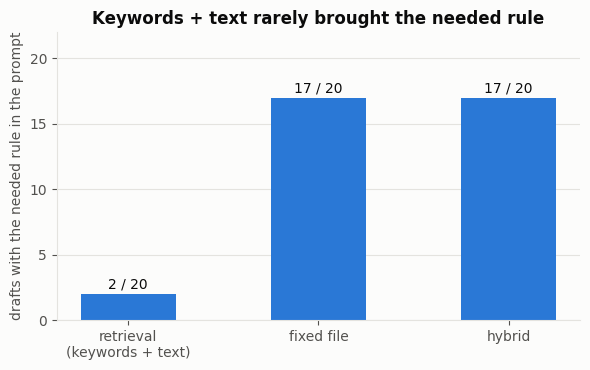

found by the search: ['st-p-01', 'st-p-02']
missing from the fixed files (text-type guides): {'st-f-08': 'email subject line', 'st-f-09': 'literature review', 'st-f-10': 'book review'}


In [23]:
rr = run()
retrieved = {c["id"] for c in rr["cases"] if c["set"] == "style" and c["query_style"] == "task"
             and any(x and x <= APP_TOP_K[c["group"].split("/")[0]] for x in c["ranks"])}
not_in_fixed = {"st-f-08": "email subject line", "st-f-09": "literature review", "st-f-10": "book review"}
ids = [c["id"] for c in STYLE_SET["cases"]]
fixed = set(ids) - set(not_in_fixed)
cover = pd.Series({"retrieval\n(keywords + text)": len(retrieved), "fixed file": len(fixed), "hybrid": len(fixed | retrieved)})

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(cover.index, cover, width=0.5, color=BLUE)
for x, v in enumerate(cover):
    ax.annotate(f"{v} / {len(ids)}", (x, v), xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_ylim(0, len(ids) + 2); ax.set_yticks(range(0, len(ids) + 1, 5))
ax.set_ylabel("drafts with the needed rule in the prompt")
ax.set_title("Keywords + text rarely brought the needed rule")
plt.tight_layout(); plt.show()
print("found by the search:", sorted(retrieved))
print("missing from the fixed files (text-type guides):", not_in_fixed)

### 5.2 Run 1: thinking on gave empty answers

qwen3.5:4b thinks before answering. For three sentences it used up to ~3,500 tokens of thinking,
filled the 4,096-token context and stopped before writing the answer. This also happened in the app,
not just in the test. **Decision 9:** thinking off for grammar and feedback.

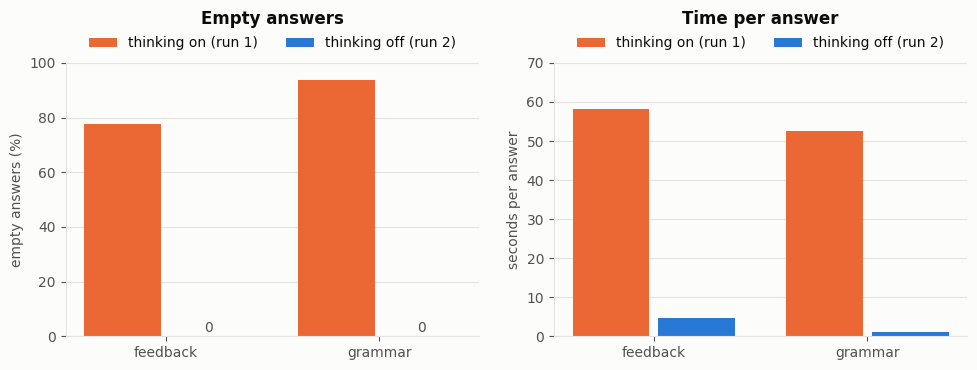

empty answers (%)                       seconds per answer  \
         thinking on (run 1) thinking off (run 2) thinking on (run 1)   
task                                                                    
feedback                77.8                  0.0                58.2   
grammar                 93.7                  0.0                52.5   

                               
         thinking off (run 2)  
task                           
feedback                  4.8  
grammar                   1.1

In [24]:
def outputs(path):
    df = pd.DataFrame(read_jsonl(path))
    df["empty"] = df["output"].str.split("\n\n---\nNote:").str[0].str.strip() == ""
    return df
r1, r2 = outputs(RAG / "phase5_run1_thinking_on/task_eval.jsonl"), outputs(RAG / "phase5_run2_thinking_off/task_eval.jsonl")
emp = pd.DataFrame({"thinking on (run 1)": 100 * r1.groupby("task")["empty"].mean(),
                    "thinking off (run 2)": 100 * r2.groupby("task")["empty"].mean()})
sec = pd.DataFrame({"thinking on (run 1)": r1.groupby("task")["seconds"].mean(),
                    "thinking off (run 2)": r2.groupby("task")["seconds"].mean()})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
grouped_bars(axes[0], emp, [ORANGE, BLUE], "empty answers (%)", ylim=(0, 100))
axes[0].set_title("Empty answers", pad=28); legend_on_top(axes[0])
grouped_bars(axes[1], sec, [ORANGE, BLUE], "seconds per answer", ylim=(0, 70))
axes[1].set_title("Time per answer", pad=28); legend_on_top(axes[1])
plt.tight_layout(); plt.show()
pd.concat({"empty answers (%)": emp, "seconds per answer": sec}, axis=1).round(1)

### 5.3 Runs 2–3: a prompt change helped most, but it is not retrieval

Run 3 added a fourth feedback heading **Structure** (thesis, topic sentences, transitions / point
of view, scene versus summary) and let grammar reword. The Structure heading gave the largest gain
of the whole evaluation. Both changes are about the model call, which a colleague tests, so they
were **removed again** and handed over (`docs/rag-evaluation.md`, Handover). Runs 4–8 use main's
prompts. One repeat per draft here, 13 drafts.

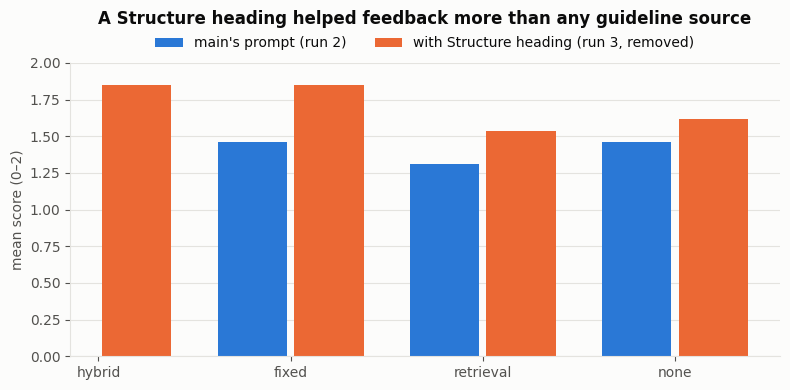

hybrid did not exist yet in run 2


,main's prompt (run 2),"with Structure heading (run 3, removed)"
hybrid,NaN,1.85
fixed,1.46,1.85
retrieval,1.31,1.54
none,1.46,1.62


In [25]:
run2 = hand_grades(RAG / "phase5_run2_thinking_off/phase5_feedback_hand_grades.json", ["fixed", "retrieval", "none"])
run3 = hand_grades(RAG / "phase5_run3_new_prompts/feedback_hand_grades.json", ["hybrid", "fixed", "retrieval", "none"])
same_cases = run2.index
order = ["hybrid", "fixed", "retrieval", "none"]
fb = pd.DataFrame({
    "main's prompt (run 2)": [run2.loc[same_cases, v].mean() if v in run2 else float("nan") for v in order],
    "with Structure heading (run 3, removed)": [run3.loc[same_cases, v].mean() for v in order],
}, index=order)
fig, ax = plt.subplots(figsize=(8, 4))
grouped_bars(ax, fb, [BLUE, ORANGE], "mean score (0–2)", ylim=(0, 2))
ax.set_title("A Structure heading helped feedback more than any guideline source", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
print("hybrid did not exist yet in run 2")
fb.round(2)

**The judge can't grade feedback.** `ministral-3:8b` gave every feedback answer 2/2 in run 3, in
every variant, and also 2/2 to empty answers in run 1:

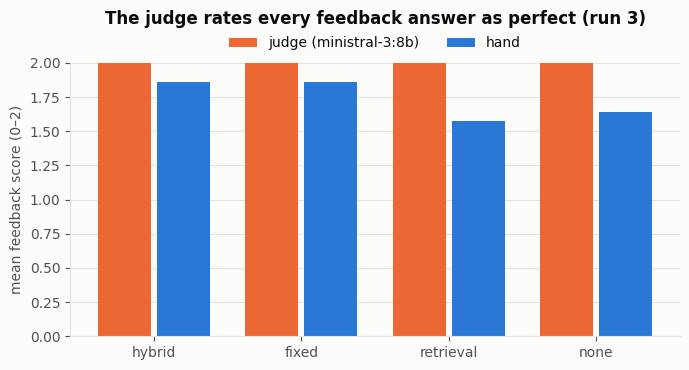

,judge (ministral-3:8b),hand
hybrid,2.0,1.86
fixed,2.0,1.86
retrieval,2.0,1.57
none,2.0,1.64


In [26]:
def judge_means(path, variants):
    df = pd.DataFrame(read_jsonl(path))
    df = df[(df["task"] == "feedback") & (df["repeat"] == 0)]
    return df.groupby("variant")["score"].mean().reindex(variants)
jh = pd.DataFrame({
    "judge (ministral-3:8b)": judge_means(RAG / "phase5_run3_new_prompts/task_eval.jsonl", order),
    "hand": run3[order].mean(),
})
fig, ax = plt.subplots(figsize=(7, 3.8))
grouped_bars(ax, jh, [ORANGE, BLUE], "mean feedback score (0–2)", ylim=(0, 2))
ax.set_title("The judge rates every feedback answer as perfect (run 3)", pad=28)
legend_on_top(ax)
plt.tight_layout(); plt.show()
jh.round(2)

### 5.4 Run 4: hybrid with keywords + text was the weakest variant

Main's prompts, 13 drafts, 3 repeats (fixed / retrieval / none from run 2, hybrid from run 4).
The search passages were mostly off-topic, and the model often **reviewed text from the guidelines
as if the user had written it** ("leakage"). Example sentences in the fixed files leaked the same
way, so they were removed.

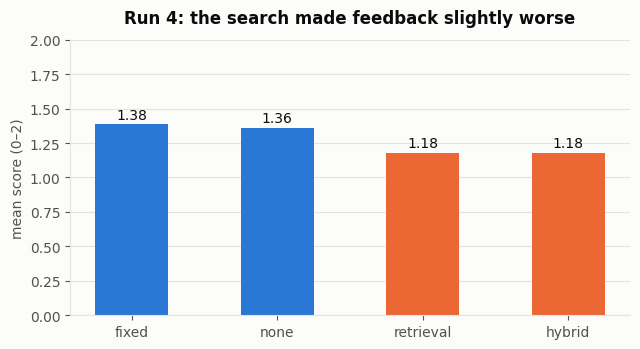

orange = with style-guide search (keywords + text), blue = without


,"feedback, 13 drafts x 3"
variant,
fixed,1.38
none,1.36
retrieval,1.18
hybrid,1.18


In [27]:
g4 = grades_long(RAG / "phase5_run4_hybrid_current_prompts/feedback_hand_grades_3_repeats.json", "run 4")
g5 = grades_long(RAG / "phase5_run5_llm_query/feedback_hand_grades_3_repeats.json", "run 5")
g6 = grades_long(RAG / "phase5_run6_oracle_retrieval/feedback_hand_grades_3_repeats.json", "run 6")
g8 = grades_long(RAG / "phase5_run8_label_query_references/feedback_hand_grades_3_repeats.json", "run 8")
m4 = g4.groupby("variant")["score"].mean().reindex(["fixed", "none", "retrieval", "hybrid"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(m4.index, m4, width=0.5, color=[BLUE, BLUE, ORANGE, ORANGE])
for x, v in enumerate(m4):
    ax.annotate(f"{v:.2f}", (x, v), xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_ylim(0, 2); ax.set_ylabel("mean score (0–2)")
ax.set_title("Run 4: the search made feedback slightly worse", pad=12)
plt.tight_layout(); plt.show()
print("orange = with style-guide search (keywords + text), blue = without")
m4.round(2).to_frame("feedback, 13 drafts x 3")

How often an answer reviewed guideline text as if it were the user's (a bullet quotes text that is
not in the draft). Same 10 drafts in every run that has them, 3 repeats:

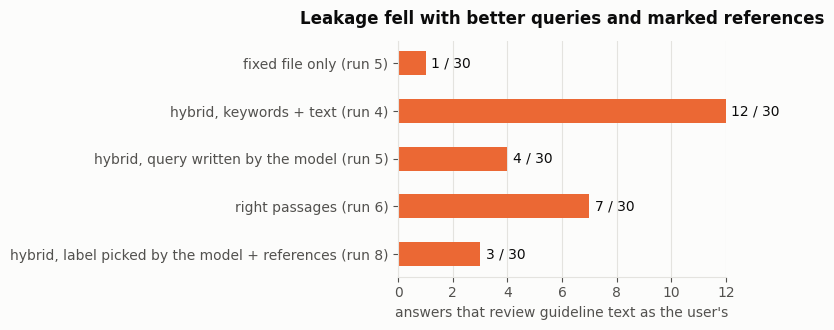

detector: a bullet quotes text not in the draft (rough: also counts paraphrased quotes)


,answers with leakage,answers
setup,,
fixed file only (run 5),1,30
"hybrid, keywords + text (run 4)",12,30
"hybrid, query written by the model (run 5)",4,30
right passages (run 6),7,30
"hybrid, label picked by the model + references (run 8)",3,30


In [28]:
import re
DRAFTS = {c["id"]: c["draft"] for c in STYLE_SET["cases"]}
TEN = ["st-f-04", "st-f-05", "st-f-06", "st-f-07", "st-f-08", "st-f-09", "st-f-10", "st-p-06", "st-p-07", "st-p-08"]
norm = lambda t: re.sub(r"[^a-z0-9 ]", "", t.lower())

def leaks(output, draft):
    for line in output.splitlines():
        m = re.match(r'\s*[-*]\s*["“]([^"”]{4,})["”]', line)
        if m and any(norm(p).strip() and norm(p).strip() not in norm(draft)
                     for p in re.split(r"\.\.\.|…", m.group(1)) if p.strip()):
            return True
    return False

def leak_rate(path, variant):
    rows = [r for r in read_jsonl(path) if r["task"] == "feedback" and r["variant"] == variant and r["id"] in TEN]
    return sum(leaks(r["output"], DRAFTS[r["id"]]) for r in rows), len(rows)

leak = pd.DataFrame([
    ("fixed file only (run 5)", *leak_rate(RAG / "phase5_run5_llm_query/task_eval.jsonl", "fixed")),
    ("hybrid, keywords + text (run 4)", *leak_rate(RAG / "phase5_run4_hybrid_current_prompts/task_eval.jsonl", "hybrid")),
    ("hybrid, query written by the model (run 5)", *leak_rate(RAG / "phase5_run5_llm_query/task_eval.jsonl", "hybrid")),
    ("right passages (run 6)", *leak_rate(RAG / "phase5_run6_oracle_retrieval/task_eval.jsonl", "oracle")),
    ("hybrid, label picked by the model + references (run 8)", *leak_rate(RAG / "phase5_run8_label_query_references/task_eval.jsonl", "hybrid")),
], columns=["setup", "answers with leakage", "answers"]).set_index("setup")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(leak.index[::-1], leak["answers with leakage"][::-1], height=0.5, color=ORANGE)
for y, v in enumerate(leak["answers with leakage"][::-1]):
    ax.annotate(f"{v} / 30", (v, y), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xlim(0, 12); ax.set_xlabel("answers that review guideline text as the user's"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Leakage fell with better queries and marked references", pad=12)
plt.tight_layout(); plt.show()
print("detector: a bullet quotes text not in the draft (rough: also counts paraphrased quotes)")
leak

### 5.5 Run 5: a query written by the model

The model first writes a ≤12-word search query naming the draft's problem (one extra call, ~1 s).
The search found the right passage more often (feedback Hit@2: 0.00 → 0.29, §3.1), and hybrid rose
from 1.18 to 1.31, but stayed below the fixed file alone (1.41, 13 drafts × 3).

*The first attempt of run 5 had a bug in the eval:* the judging pass regenerated answers with the
last variant's settings. It was stopped, fixed, and its files kept as `INVALID_*` with a README.

### 5.6 Retrieval options: the query is the bottleneck

`tests/eval/rag/try_retrieval_options.py`: no answers generated, 14 feedback drafts, existing
indexes. Search methods × queries, chunk 1000/400. The test set answer is the best case for the query
(not available in the app).

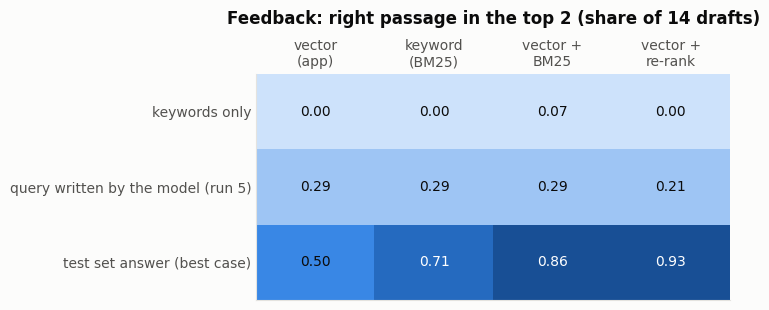

,vector\n(app),keyword\n(BM25),vector +\nBM25,vector +\nre-rank
keywords only,0.00,0.00,0.07,0.00
query written by the model (run 5),0.29,0.29,0.29,0.21
test set answer (best case),0.50,0.71,0.86,0.93


In [29]:
opts = pd.DataFrame(json.loads((RAG / "retrieval_options.json").read_text()))
fb_opts = opts[(opts["group"].str.startswith("feedback")) & (opts["chunks"] == "1000/400")].copy()
fb_opts["hit2"] = fb_opts["ranks"].apply(lambda rs: any(r and r <= 2 for r in rs))
grid = fb_opts.pivot_table(index="query", columns="search", values="hit2", aggfunc="mean")
grid = grid.loc[["keywords", "llm", "issue"], ["vector", "bm25", "hybrid", "vector+rerank"]]
grid.index = [QUERY_NAMES["keywords"], QUERY_NAMES["llm"] + " (run 5)", QUERY_NAMES["issue"]]
grid.columns = ["vector\n(app)", "keyword\n(BM25)", "vector +\nBM25", "vector +\nre-rank"]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
score_grid(ax, grid, vmax=1, fmt="{:.2f}", cmap=RAMP_CMAP)
ax.set_title("Feedback: right passage in the top 2 (share of 14 drafts)", pad=36)
plt.tight_layout(); plt.show()
grid.round(2)

- With a poor query, no search method helps. With a good one, every method works, and re-ranking
  brings the right passage into the top 2 for 13 of 14 drafts.
- The queries written by the model named the wrong problem, e.g. "How to vary sentence structure" for a
  literature review that only summarises sources, or "Show don't tell" for a point-of-view switch.
- Chunk sizes 500 and 1500 did not change this (`retrieval_options.txt`).

### 5.7 Runs 6 and 7: would perfect retrieval help?

Run 6 forces the right passages into the prompt (oracle). Run 7 repeats a small check with
`ministral-3:8b` on 6 drafts.

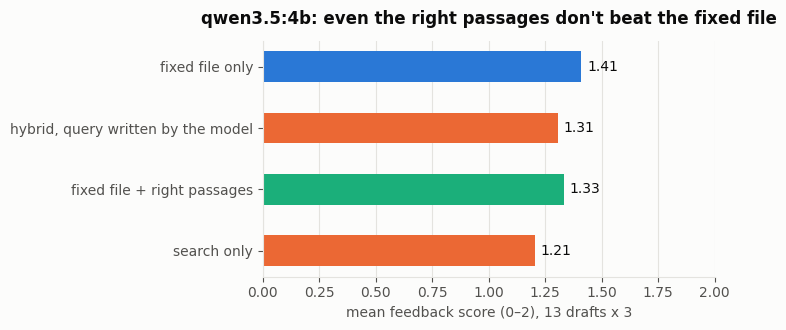

,ministral-3:8b,qwen3.5:4b
variant,,
fixed,0.83,1.33
hybrid,0.89,1.17
right passages,0.94,1.11


In [30]:
thirteen = sorted(set(g5["id"]) - {"st-f-02"})
perfect = pd.Series({
    "fixed file only": g5[(g5.variant == "fixed") & g5.id.isin(thirteen)].score.mean(),
    "hybrid, query written by the model": g5[(g5.variant == "hybrid") & g5.id.isin(thirteen)].score.mean(),
    "fixed file + right passages": g6[g6.id.isin(thirteen)].score.mean(),
    "search only": g5[(g5.variant == "retrieval") & g5.id.isin(thirteen)].score.mean(),
})
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(perfect.index[::-1], perfect[::-1], height=0.5, color=[ORANGE, AQUA, ORANGE, BLUE])
for y, v in enumerate(perfect[::-1]):
    ax.annotate(f"{v:.2f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xlim(0, 2); ax.set_xlabel("mean feedback score (0–2), 13 drafts x 3"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("qwen3.5:4b: even the right passages don't beat the fixed file", pad=12)
plt.tight_layout(); plt.show()

g7 = pd.concat([grades_long(RAG / "phase5_run7_ministral/feedback_hand_grades.json", "run 7"),
                grades_long(RAG / "phase5_run7_ministral/feedback_hand_grades_5_drafts.json", "run 7")])
six = sorted(g7["id"].unique())
q4 = pd.concat([g5[g5.variant.isin(["fixed", "hybrid"])], g6]).query("id in @six")
pd.DataFrame({"ministral-3:8b": g7.groupby("variant").score.mean(),
              "qwen3.5:4b": q4.groupby("variant").score.mean()}).rename(index={"oracle": "right passages"}).round(2)

- With qwen3.5:4b, the right passages (1.33) score like hybrid (1.31) and below the fixed file
  (1.41). The model already knows most of this advice; extra text can also distract it.
- ministral-3:8b is weaker at feedback than qwen3.5:4b, and the passages give it only a small,
  noisy gain (6 drafts). A clearly larger model is the real test (§6).

### 5.8 Run 8: label picked by the model + re-ranking + references (the app now)

Two fixes for what §5.4–5.6 found:
1. **Query (label picked by the model):** `style_query` asks the model to pick one item from
   `problem_labels`, a list of guide topics (multiple choice instead of writing a query). The label is the search query, and the top 30 are re-ranked.
2. **References:** each passage is marked `REFERENCE n, from "<guide>" (advice from a style guide,
   not the user's text; do not review or quote it)`.

Tested on 10 feedback drafts (the 4 drafts every variant always got right left out), 3 repeats.

In [31]:
lab = pd.DataFrame(json.loads((RAG / "label_queries_check.json").read_text()))
lab["picked"] = lab["picked"].str[0]
lab["right passage in top 2"] = lab["rank_rerank"].apply(lambda r: "yes" if r and r <= 2 else "no")
display(lab[["id", "issue", "picked", "rank_vector", "rank_rerank", "right passage in top 2"]]
        .rename(columns={"issue": QUERY_NAMES["issue"], "picked": "label picked by the model (qwen3.5:4b)",
                         "rank_vector": "rank (vector)", "rank_rerank": "rank (re-ranked)"}))

,id,test set answer (best case),label picked by the model (qwen3.5:4b),rank (vector),rank (re-ranked),right passage in top 2
0,st-f-04,first and second person in a formal essay,first or second person in formal writing,1.0,1.0,yes
1,st-f-05,no clear thesis: the introduction lists topics without a central claim,no clear thesis or central claim,1.0,1.0,yes
2,st-f-06,paragraph without a topic sentence,no clear thesis or central claim,NaN,NaN,no
3,st-f-07,missing transitions between ideas,no clear thesis or central claim,NaN,NaN,no
4,st-f-08,vague email subject line,email with a vague subject line,2.0,1.0,yes
5,st-f-09,literature review that only summarises sources one by one,literature review that summarises sources one by one instead of synthesising them,1.0,2.0,yes
6,st-f-10,book review that only retells the plot,book review that only retells the plot instead of evaluating the book,8.0,NaN,no
7,st-p-06,point of view switches from first person to third person,point of view switches between first and third person,6.0,1.0,yes
8,st-p-07,third person limited suddenly becomes omniscient,point of view switches between first and third person,6.0,1.0,yes
9,st-p-08,telling emotions instead of showing them,telling emotions instead of showing them,NaN,2.0,yes


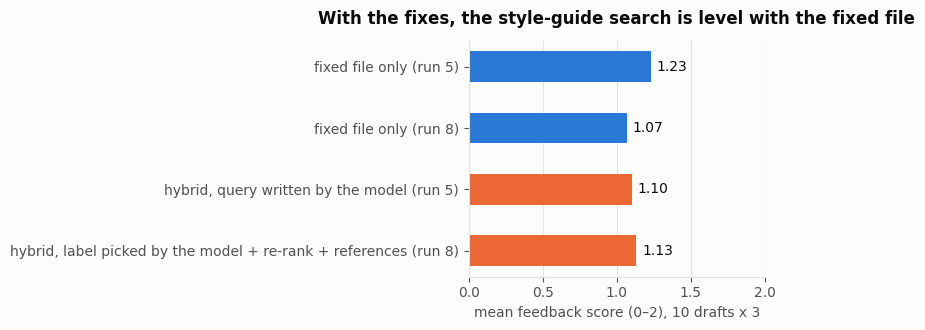

blue = fixed file only (two runs of the same setup: the gap between them is the noise), orange = with style-guide search


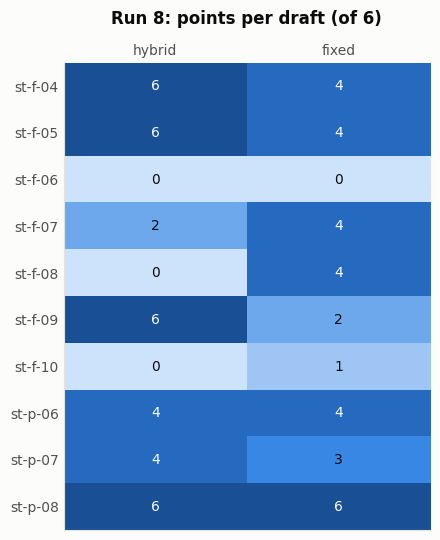

variant,hybrid,fixed,problem
id,,,
st-f-04,6,4,first and second person in a formal essay
st-f-05,6,4,no clear thesis: the introduction lists topics without a central claim
st-f-06,0,0,paragraph without a topic sentence
st-f-07,2,4,missing transitions between ideas
st-f-08,0,4,vague email subject line
st-f-09,6,2,literature review that only summarises sources one by one
st-f-10,0,1,book review that only retells the plot
st-p-06,4,4,point of view switches from first person to third person
st-p-07,4,3,third person limited suddenly becomes omniscient


In [32]:
compare = pd.Series({
    "fixed file only (run 5)": g5[(g5.variant == "fixed") & g5.id.isin(TEN)].score.mean(),
    "fixed file only (run 8)": g8[g8.variant == "fixed"].score.mean(),
    "hybrid, query written by the model (run 5)": g5[(g5.variant == "hybrid") & g5.id.isin(TEN)].score.mean(),
    "hybrid, label picked by the model + re-rank + references (run 8)": g8[g8.variant == "hybrid"].score.mean(),
})
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(compare.index[::-1], compare[::-1], height=0.5, color=[ORANGE, ORANGE, BLUE, BLUE])
for y, v in enumerate(compare[::-1]):
    ax.annotate(f"{v:.2f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xlim(0, 2); ax.set_xlabel("mean feedback score (0–2), 10 drafts x 3"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("With the fixes, the style-guide search is level with the fixed file", pad=12)
plt.tight_layout(); plt.show()
print("blue = fixed file only (two runs of the same setup: the gap between them is the noise), orange = with style-guide search")

per_draft = g8.pivot_table(index="id", columns="variant", values="score", aggfunc="sum")[["hybrid", "fixed"]]
fig, ax = plt.subplots(figsize=(4.5, 5.5))
score_grid(ax, per_draft, vmax=6, fmt="{:.0f}", cmap=RAMP_CMAP)
ax.set_title("Run 8: points per draft (of 6)", pad=28)
plt.tight_layout(); plt.show()
issues = {c["id"]: c["issue"] for c in STYLE_SET["cases"]}
per_draft.assign(problem=[issues[i] for i in per_draft.index])

- The right label is picked for 7 of 10 drafts, and the right passage reaches the top 2 for 7 of 10
  (before: about 3 of 10).
- Feedback with the style-guide search is now level with the fixed file (1.13 vs 1.07 and 1.23 for
  the same fixed setup in two runs), instead of below it.
- It clearly helps the literature review (6 vs 2 points), thesis and first/second person drafts.
- It still hurts the email subject line and the book review. The *Book Reviews* guide talks to its
  reader ("You can and should…"), and the model reviewed those sentences as the user's text in all 3
  answers despite the REFERENCE label.

### 5.9 Grammar

Grammar is scored by the judge (mean of 3 repeats). The judge accepts US-style quotes ("…'never
again'…") as British style for **st-p-09**, which is wrong, so that case is set to 0 by hand.

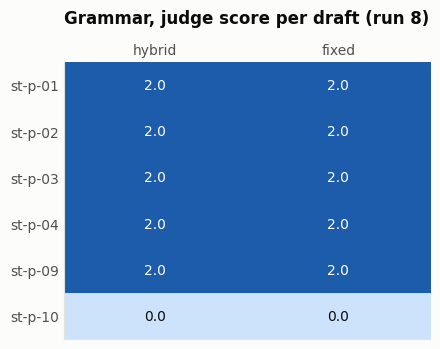

variant,hybrid,fixed
judge,1.67,1.67
with st-p-09 corrected,1.33,1.33


In [33]:
g8g = pd.DataFrame(read_jsonl(RAG / "phase5_run8_label_query_references/task_eval_grammar.jsonl"))
g8g = g8g.pivot_table(index="id", columns="variant", values="score", aggfunc="mean")[["hybrid", "fixed"]]
fig, ax = plt.subplots(figsize=(4.5, 3.6))
score_grid(ax, g8g, fmt="{:.1f}")
ax.set_title("Grammar, judge score per draft (run 8)", pad=28)
plt.tight_layout(); plt.show()
corrected = g8g.copy(); corrected.loc["st-p-09"] = 0
pd.DataFrame({"judge": g8g.mean(), "with st-p-09 corrected": corrected.mean()}).round(2).T

- Comma splices, run-on sentences and subject–verb agreement (incl. either/or) are fixed with and
  without the style-guide search.
- **Dangling modifiers (st-p-10) are never fixed** and **UK nested quotes (st-p-09) never
  converted**, in any run, even with rewording allowed (run 3). A limit of the 4B model.

### 5.10 Summary of Phase 5

| | Before | Now |
|---|---|---|
| Right style-guide passage in the top 2 (feedback) | 0 / 13 (keywords + text) | 9 / 14 (label picked by the model, re-ranked) |
| Feedback score vs the fixed file alone | below it (run 4: 1.18 vs 1.38) | level (run 8: 1.13 vs 1.07–1.23) |
| Answers reviewing guideline text as the user's | 12 / 39 (run 4) | 3 / 30 (run 8; all in the book review) |
| Empty answers | 83% (thinking on) | 0% |
| Time per answer | ~55 s | ~5 s (+ ~1 s for the label) |

## 6. Still open

- **Larger task model** (colleague's test): does it make more of the style-guide passages? With
  qwen3.5:4b they add little to what the model already knows (§5.7). Command:
  `run_task_eval.py --model <model> --variants hybrid,fixed,oracle --tasks feedback --no-judge`.
- **Leakage from guides that address the reader** (*Book Reviews*): drop such passages or strip
  second-person sentences from references.
- **Label lists vs. the test set:** the labels and the test problems both come from the guides'
  topics, so the label picked by the model may look better here than on real texts.
- **Dangling modifiers and UK quotes** are never fixed by the 4B model.
- **Feedback evaluation needs hand grading** or a much stronger judge (§5.3).
- **Small test sets.** One case moves Q&A Hit@3 by 0.04, feedback by 0.03–0.10; the same setup
  varied by ±0.15 between runs. Only patterns that repeat are treated as findings.